# Figure 6 · Recovery of observed galaxy shapes

**Question:** How well do reconstructed ellipticities agree with the observed JWST reference?

**Status:** a clearly labeled preview from the completed legacy baseline only.
Final models and test evaluation are pending. This is observed ellipticity,
not calibrated shear or a shear-bias requirement plot.

The same JWST/native/bilinear/bicubic/SR success intersection is used in every
panel; full-population failure counts remain visible in the notebook.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

# Works from the repository root or from paper_figures/.
here = Path.cwd()
workspace = here if (here / 'figure_utils.py').exists() else here / 'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import (ROOT, FIGURES, DATA, COLORS, style, read_json, export,
                          panel, box, arrow, verified_sources, completed_evaluation,
                          run_inventory, sha)
%matplotlib inline
style()
VERSION = 'v01'

In [2]:
FIGSIZE = (7.2, 6.3)
analysis = ROOT / 'runs/validation-shapes-full50-best'
provenance = completed_evaluation(analysis)
report = read_json(analysis / 'report.json')
with np.load(analysis / 'measurements.npz', allow_pickle=False) as saved:
    measurements = dict(saved)
methods = ['native', 'bilinear', 'bicubic', 'sr']
common = measurements['jwst_good'].copy()
for method in methods: common &= measurements[method + '_good']
assert int(common.sum()) == report['summary']['common_successes']
assert len(np.unique(measurements['object_ids'])) == len(common)
display(pd.DataFrame({'method':['jwst', *methods],
    'failures_on_all_validation':[int((~measurements[m+'_good']).sum()) for m in ['jwst', *methods]],
    'total_objects':len(common)}))
print(f'All panels use the same {common.sum():,} object IDs; checkpoint epoch {provenance["epoch"]}.')

,method,failures_on_all_validation,total_objects
0,jwst,218,2118
1,native,377,2118
2,bilinear,379,2118
3,bicubic,490,2118
4,sr,73,2118


All panels use the same 1,523 object IDs; checkpoint epoch 49.


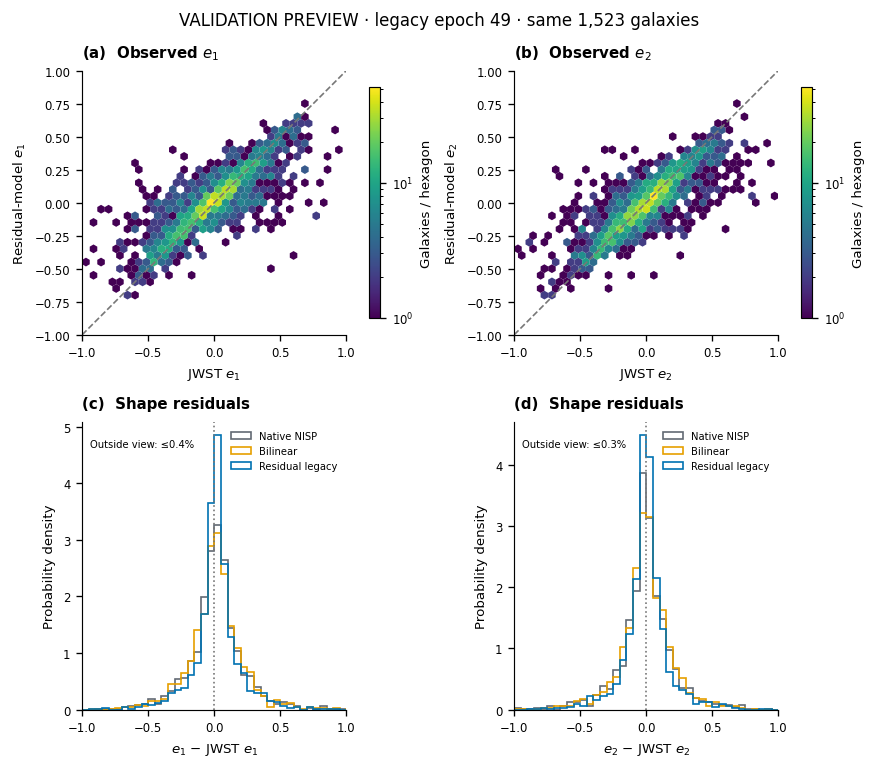

In [3]:
fig, axes = plt.subplots(2, 2, figsize=FIGSIZE, layout='constrained')
reference = measurements['jwst_e'][common]
prediction = measurements['sr_e'][common]
for component, ax in enumerate(axes[0]):
    density = ax.hexbin(reference[:, component], prediction[:, component], gridsize=35,
        extent=(-1, 1, -1, 1), mincnt=1, bins='log', cmap='viridis', linewidths=0)
    ax.plot([-1, 1], [-1, 1], '--', color='#777777', lw=1)
    ax.set(xlim=(-1, 1), ylim=(-1, 1), xlabel=f'JWST $e_{component+1}$',
           ylabel=f'Residual-model $e_{component+1}$', aspect='equal')
    panel(ax, chr(97+component), f'Observed $e_{component+1}$')
    fig.colorbar(density, ax=ax, label='Galaxies / hexagon', shrink=.8)
for component, ax in enumerate(axes[1]):
    arrays = {m:measurements[m+'_e'][common, component]-reference[:, component]
              for m in ['native', 'bilinear', 'sr']}
    bins = np.linspace(-2, 2, 81)
    for method, delta in arrays.items():
        label = {'native':'Native NISP', 'bilinear':'Bilinear', 'sr':'Residual legacy'}[method]
        ax.hist(delta, bins=bins, density=True, histtype='step', color=COLORS[method], label=label)
    ax.axvline(0, ls=':', lw=1, color='#777777')
    ax.set(xlabel=f'$e_{component+1}$ − JWST $e_{component+1}$', ylabel='Probability density', xlim=(-1, 1))
    tails = max(float((np.abs(delta)>1).mean()) for delta in arrays.values())
    ax.text(.03, .94, f'Outside view: ≤{100*tails:.1f}%', transform=ax.transAxes, ha='left', va='top', fontsize=6)
    panel(ax, chr(99+component), 'Shape residuals')
    ax.legend(frameon=False, loc='upper right', fontsize=6)
fig.suptitle(f'VALIDATION PREVIEW · legacy epoch {provenance["epoch"]} · same {common.sum():,} galaxies', fontsize=10)
plt.show()

In [4]:
paths = export(fig, f'fig06_observed_shapes_{VERSION}', '06_observed_shapes.ipynb',
    [analysis/'measurements.npz', analysis/'provenance.json', analysis/'report.json'],
    dict(figsize=FIGSIZE, common_object_ids=measurements['object_ids'][common].tolist(),
         checkpoint_sha256=provenance['checkpoint_sha256'], split='validation'),
    status='legacy-only validation preview; not a final model comparison')

Exported: fig06_observed_shapes_v01.pdf, fig06_observed_shapes_v01.svg, fig06_observed_shapes_v01.png


## Working caption and review choices

Observed ellipticity recovery on the common-success validation population.
The upper panels compare reconstructed and observed JWST components; the dashed
line denotes equality. The lower panels compare residual distributions for
native NISP, bilinear interpolation and the legacy reconstruction. Shapes are
measured from signed linear-intensity images with the declared fixed-moment
contract. Failure counts are evaluated on the full validation sample separately.

- Decide whether the final figure should use one column per model instead.
- Keep e1/e2; do not relabel `observed_shape.g` as an independent shear result.
- Identity is a visual reference, not a calibrated shear-bias estimate.
- If axes are tightened, retain explicit tail counts and the full saved data.
- Colors and plotting populations must stay consistent across all models.